# ZShield EDA: PaySim
Balaa, data and features. Source: PaySim (Kaggle, synthetic mobile-money transactions).
Charts are saved to `docs/eda/` for the deck. Legit = blue, fraud = orange in every chart.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd()
OUT = ROOT / "docs/eda"; OUT.mkdir(parents=True, exist_ok=True)
LEGIT, FRAUD = "#2a78d6", "#eb6834"                       # validated categorical slots 1 and 2
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()

df = pd.read_csv(ROOT / "data/paysim.csv")
df.shape

(6362620, 11)

## 1. Data quality

In [2]:
tc = df[df.type.isin(["TRANSFER", "CASH_OUT"])]
quality = {
    "rows": len(df), "null_cells": int(df.isna().sum().sum()), "duplicate_rows": int(df.duplicated().sum()),
    "negative_amounts": int((df.amount < 0).sum()), "zero_amounts": int((df.amount == 0).sum()),
    "fraud": int(df.isFraud.sum()), "fraud_rate_pct": round(100 * df.isFraud.mean(), 3),
    "isFlaggedFraud": int(df.isFlaggedFraud.sum()),
    "senders_seen_once_pct": round(100 * (df.nameOrig.value_counts() == 1).mean(), 2),
    "transfer_cashout_sender_books_off_pct": round(100 * (np.abs(tc.newbalanceOrig + tc.amount - tc.oldbalanceOrg) > 0.01).mean(), 1),
    "transfer_cashout_recipient_books_off_pct": round(100 * (np.abs(tc.oldbalanceDest + tc.amount - tc.newbalanceDest) > 0.01).mean(), 1),
}
quality

{'rows': 6362620,
 'null_cells': 0,
 'duplicate_rows': 0,
 'negative_amounts': 0,
 'zero_amounts': 16,
 'fraud': 8213,
 'fraud_rate_pct': np.float64(0.129),
 'isFlaggedFraud': 16,
 'senders_seen_once_pct': np.float64(99.85),
 'transfer_cashout_sender_books_off_pct': np.float64(90.3),
 'transfer_cashout_recipient_books_off_pct': np.float64(22.7)}

## 2. Fraud happens only in TRANSFER and CASH_OUT

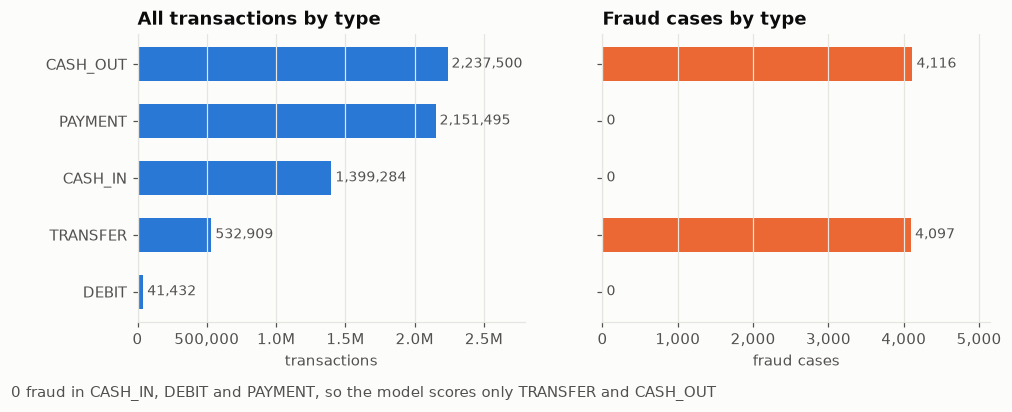

In [3]:
by_type = df.groupby("type").isFraud.agg(rows="count", fraud="sum").sort_values("rows")
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, col, color, title in [(a, "rows", LEGIT, "All transactions by type"),
                              (b, "fraud", FRAUD, "Fraud cases by type")]:
    ax.barh(by_type.index, by_type[col], color=color, height=0.6)
    ax.set_title(title); ax.grid(axis="y", visible=False)
    for y, v in enumerate(by_type[col]):
        ax.text(v, y, f" {v:,}", va="center", color=INK2, fontsize=9)
    ax.set_xlim(0, by_type[col].max() * 1.25)
a.set_xlabel("transactions"); b.set_xlabel("fraud cases")
for ax in (a, b):
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M" if v >= 1e6 else f"{v:,.0f}"))
fig.suptitle("0 fraud in CASH_IN, DEBIT and PAYMENT, so the model scores only TRANSFER and CASH_OUT",
             x=0.01, ha="left", fontsize=10, color=INK2, y=-0.06)
save(fig, "1_fraud_by_type.png")

## 3. Amounts (TRANSFER and CASH_OUT)

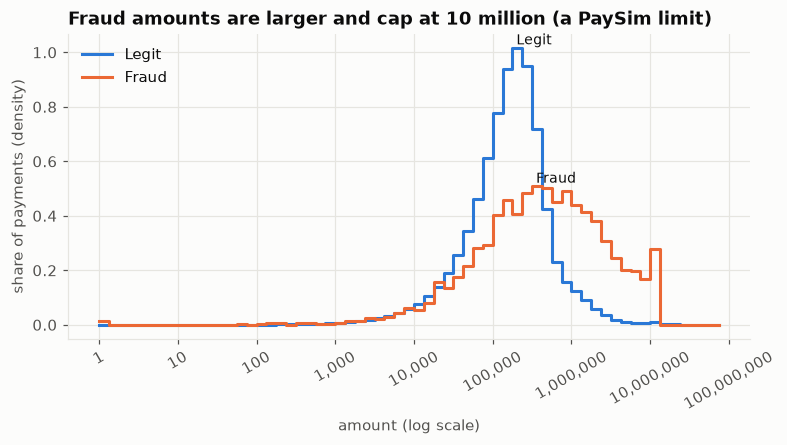

In [4]:
bins = np.linspace(0, 8, 65)
fig, ax = plt.subplots(figsize=(8, 3.6))
for lab, color, name in [(0, LEGIT, "Legit"), (1, FRAUD, "Fraud")]:
    x = np.log10(tc.loc[tc.isFraud == lab, "amount"].clip(lower=1))
    h, e = np.histogram(x, bins=bins, density=True)
    ax.step(e[:-1], h, where="post", color=color, linewidth=2, label=name)
    peak = e[h.argmax()]
    ax.text(peak, h.max(), f" {name}", color=INK, fontsize=9, va="bottom")
ax.set_xticks(range(0, 9)); ax.set_xticklabels([f"{10**k:,.0f}" for k in range(0, 9)], rotation=30)
ax.set_xlabel("amount (log scale)"); ax.set_ylabel("share of payments (density)")
ax.set_title("Fraud amounts are larger and cap at 10 million (a PaySim limit)")
ax.legend(frameon=False, loc="upper left")
save(fig, "2_amount_distribution.png")

## 4. Activity over time and the time-based split

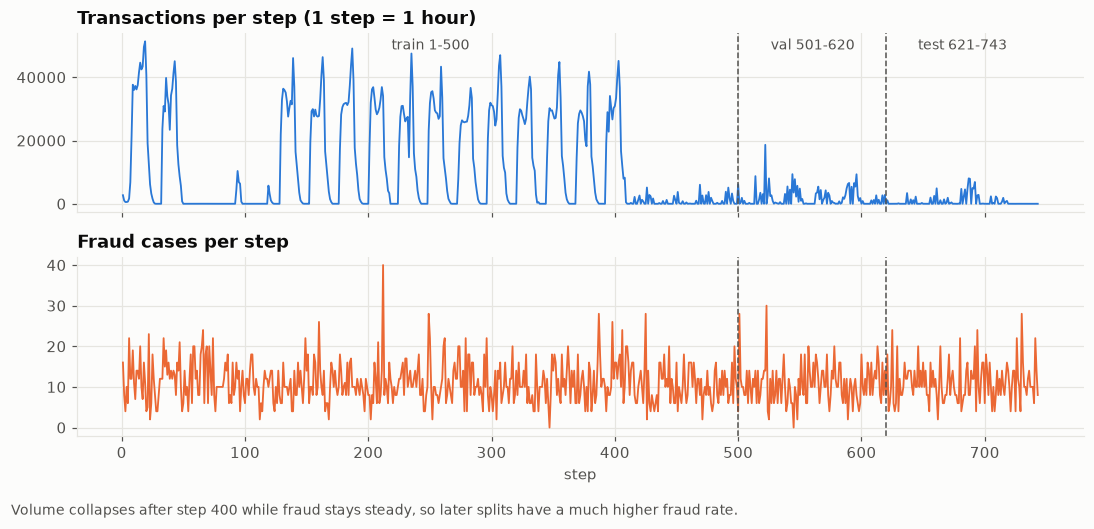

In [5]:
per_step = df.groupby("step").isFraud.agg(rows="count", fraud="sum")
fig, (a, b) = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
a.plot(per_step.index, per_step.rows, color=LEGIT, linewidth=1.2)
b.plot(per_step.index, per_step.fraud, color=FRAUD, linewidth=1.2)
a.set_title("Transactions per step (1 step = 1 hour)"); b.set_title("Fraud cases per step")
for ax in (a, b):
    for x in (500, 620):
        ax.axvline(x, color=INK2, linewidth=1, linestyle="--")
for x0, x1, name in [(1, 500, "train 1-500"), (501, 620, "val 501-620"), (621, 743, "test 621-743")]:
    a.text((x0 + x1) / 2, per_step.rows.max() * 0.95, name, ha="center", color=INK2, fontsize=9)
b.set_xlabel("step")
fig.text(0.01, -0.03, "Volume collapses after step 400 while fraud stays steady, so later splits have a much higher fraud rate.",
         color=INK2, fontsize=9)
fig.tight_layout()
save(fig, "3_activity_over_time.png")

## 5. Fraud rate by hour of day

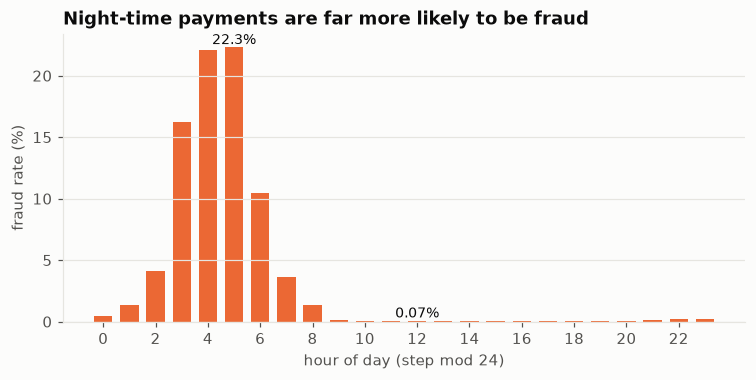

In [6]:
df["hour"] = df.step % 24
rate = df.groupby("hour").isFraud.mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(rate.index, rate.values, color=FRAUD, width=0.7)
ax.grid(axis="x", visible=False)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (step mod 24)"); ax.set_ylabel("fraud rate (%)")
top = rate.idxmax(); ax.text(top, rate.max(), f"{rate.max():.1f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.text(12, rate.loc[12], f"{rate.loc[12]:.2f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Night-time payments are far more likely to be fraud")
save(fig, "4_fraud_rate_by_hour.png")

## 6. Balance patterns (TRANSFER and CASH_OUT)

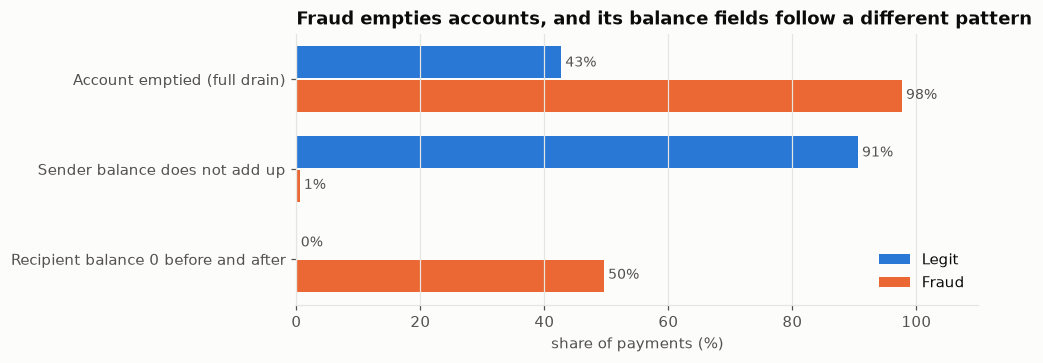

isFraud,0,1
Account emptied (full drain),42.7,97.7
Sender balance does not add up,90.6,0.5
Recipient balance 0 before and after,0.1,49.6


In [7]:
pat = pd.DataFrame({
    "Account emptied (full drain)": (tc.amount >= tc.oldbalanceOrg) & (tc.oldbalanceOrg > 0),
    "Sender balance does not add up": np.abs(tc.newbalanceOrig + tc.amount - tc.oldbalanceOrg) > 0.01,
    "Recipient balance 0 before and after": (tc.oldbalanceDest == 0) & (tc.newbalanceDest == 0),
})
share = pat.groupby(tc.isFraud).mean().T * 100
y = np.arange(len(share)); h = 0.36
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(y - h / 2 - 0.01, share[0], height=h, color=LEGIT, label="Legit")
ax.barh(y + h / 2 + 0.01, share[1], height=h, color=FRAUD, label="Fraud")
for i, (l, f) in enumerate(zip(share[0], share[1])):
    ax.text(l, i - h / 2, f" {l:.0f}%", va="center", fontsize=9, color=INK2)
    ax.text(f, i + h / 2, f" {f:.0f}%", va="center", fontsize=9, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(share.index); ax.invert_yaxis()
ax.set_xlim(0, 110); ax.set_xlabel("share of payments (%)"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Fraud empties accounts, and its balance fields follow a different pattern")
save(fig, "5_balance_patterns.png")
share.round(1)

## 7. Leakage check: how much does one feature alone separate fraud?
PaySim generates fraud with tell-tale balance fields. If a single raw feature scores near 1.0 AUC,
the model's test score says more about the simulator than about real-world performance.

In [8]:
import sys; sys.path.insert(0, str(ROOT))
from features.features import base_features
test = tc[tc.step > 620]
F = pd.DataFrame([base_features(r) for r in test.to_dict("records")], index=test.index)
auc = {c: round(max(roc_auc_score(test.isFraud, F[c]), 1 - roc_auc_score(test.isFraud, F[c])), 4)
       for c in ["err_bal_orig", "err_bal_dest", "full_drain", "amt_to_bal", "amount", "hour"]}
(OUT / "single_feature_auc.json").write_text(json.dumps({"split": "test steps 621-743, TRANSFER+CASH_OUT",
                                                         "rows": len(test), "auc": auc}, indent=2) + "\n")
(OUT / "quality.json").write_text(json.dumps(quality, indent=2) + "\n")
pd.Series(auc).sort_values(ascending=False)

err_bal_orig    0.9393
amt_to_bal      0.8904
err_bal_dest    0.7477
full_drain      0.7225
amount          0.6803
hour            0.6327
dtype: float64